# What a Finite Kernel Buys an MLP (JAX/Flax NNX)

Every multilayer perceptron is built from one primitive: a linear map followed by a pointwise nonlinearity, $h = \sigma(w^\top x + b)$. The activation $\sigma$ is the part nobody can quite justify. This notebook asks one question: what if the primitive were not a linear map plus an activation, but a **finite, explicit, positive-definite kernel**, a similarity between the input and a learned center, with no $\sigma$ at all? The kernel is the **Yat kernel**, and once the unit is a kernel you get locality, attribution, geometry, capacity control, and a feature map you can write down, for free. We build that layer in Flax NNX, turn each claim into an assertion, train it end to end, and draw the result.

- **Companion (code):** https://www.tahabouhsine.com/blog/yat-mlp-jax-flax-nnx/
- **Explainer (concept + interactive):** https://www.tahabouhsine.com/blog/what-a-finite-kernel-buys-an-mlp/

Every number below is from a real run. Outputs are written to `/kaggle/working`. By [Taha Bouhsine](https://www.tahabouhsine.com).

## What this notebook covers

We define the Yat unit $k_{b,\varepsilon}(W,x) = (W^\top x + b)^2 / (\lVert x - W\rVert^2 + \varepsilon)$, the kernel that replaces the activation. We check in code that it is **positive definite** (a Mercer kernel, so it has an RKHS) and **nonnegative** (so the readout can normalize into honest attribution). We write down its **exact finite feature map** and verify the identity $\phi(W)^\top\phi(x) = (W^\top x + b)^2$ to machine precision. We train a `YatMLP` (one Yat layer plus a linear readout, no activation function anywhere) on two-moons and watch the prototypes migrate onto the data. Then we measure the affordances the kernel buys: **lazy-loading sparsity** (only the near prototypes fire), **bounded off-distribution response** (no confident extrapolation), the **RKHS capacity** scalar, and the **force field** that pulls every prototype toward its data with no dead half-space. Each code block is lifted from the companion; before each is the math and intuition from the explainer. A handful of faithful plots and a GIF, all computed from the real trained objects, close it out.

In [1]:
# Kaggle preinstalls numpy, jax, matplotlib, sklearn, torch, PIL. flax/optax/imageio usually need a touch.
!pip install -q -U flax optax imageio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 525.1/525.1 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 74.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.5/85.5 MB 21.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


## Inline rendering helper

Kaggle does not reliably animate `IPython.display.Image` GIFs, so every figure and GIF this notebook produces is embedded as a base64 `<img>` (GIFs animate, PNGs show) right after it is saved, and gathered again in the final gallery.

In [2]:
# Robust inline rendering: animated GIFs as base64 <img> (Kaggle does not reliably animate IPython.Image gifs)
import base64
from IPython.display import HTML, display
def _img(path, **kw):
    p = str(path); mime = 'image/gif' if p.endswith('.gif') else 'image/png'
    b64 = base64.b64encode(open(p, 'rb').read()).decode()
    return HTML(f'<img src="data:{mime};base64,{b64}" style="max-width:100%;border-radius:6px"/>')

## Setup: imports and the output directory

Everything is computed in **JAX** (`jax.numpy` for the array math), the layer is a **Flax NNX** module, training uses **Optax**, and the figures are drawn with **Matplotlib** on the non-interactive `Agg` backend so they rasterize to memory; **imageio** assembles the one animated GIF. All artifacts are written to `/kaggle/working`, which is what the notebook surfaces at the end.

In [3]:
import jax, jax.numpy as jnp
from flax import nnx
import optax
import numpy as np
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import imageio.v2 as imageio

PUB = Path('/kaggle/working'); PUB.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 110
INK, PAPER = '#1d1d1f', '#fbf8f1'
C0, C1 = '#c1440e', '#2a6f97'   # two class colors
print('jax', jax.__version__)

jax 0.10.2


## The unit

A Yat unit measures the input against a learned prototype $W_u\in\mathbb{R}^d$ with the kernel

$$
y_u(x) \;=\; \alpha_u\,\underbrace{\frac{(W_u^\top x + b)^2}{\lVert x - W_u\rVert^2 + \varepsilon}}_{k_{b,\varepsilon}(W_u,\,x)} .
$$

There is no $\sigma$. The numerator is a **squared alignment** (how much $x$ points along $W_u$); the denominator is an **inverse-multiquadric distance gate** (how close $x$ sits to $W_u$). The unit fires when the input is both aligned with and near its center, a single localized peak at $x = W_u$. A ReLU unit carries only a *direction* and fires across an entire half-space; the kernel unit carries a *point*. A whole layer is a bank of these with no activation function anywhere in it.

In NNX the prototypes are the parameters; $b$ and $\varepsilon$ are learned through a softplus so they stay admissible ($b\ge 0$, $\varepsilon>0$). The distance is expanded as $\lVert x - W_u\rVert^2 = \lVert x\rVert^2 + \lVert W_u\rVert^2 - 2 W_u^\top x$ so the whole unit reduces to a matmul plus two norm vectors.

In [4]:
class YatLayer(nnx.Module):
    """A layer of Yat-kernel units. No activation function."""
    def __init__(self, d_in, n_units, *, rngs: nnx.Rngs, b0=0.5, eps0=0.5):
        self.W = nnx.Param(jax.random.normal(rngs.params(), (n_units, d_in)) * 0.7)
        self.log_b = nnx.Param(jnp.full((), jnp.log(jnp.expm1(b0))))     # softplus⁻¹(b₀)
        self.log_eps = nnx.Param(jnp.full((), jnp.log(jnp.expm1(eps0))))

    def __call__(self, x):                              # x: [..., d_in]
        b = jax.nn.softplus(self.log_b.value)
        eps = jax.nn.softplus(self.log_eps.value)
        dot = x @ self.W.value.T                        # [..., n_units]  = x·Wᵤ
        xn = jnp.sum(x ** 2, -1, keepdims=True)         # ‖x‖²
        wn = jnp.sum(self.W.value ** 2, -1)             # ‖Wᵤ‖²
        dist2 = xn + wn - 2.0 * dot                     # ‖x − Wᵤ‖²
        return (dot + b) ** 2 / (dist2 + eps)           # the kernel is the nonlinearity

## It is a kernel: positive definite and nonnegative

Two independent properties make this a *kernel* and not just a clever activation. It is **nonnegative** ($b\ge 0$ keeps the numerator a square, the denominator is positive). And it is **positive definite**: $k_{b,\varepsilon}$ is the Schur product of a degree-2 polynomial kernel $(W^\top x + b)^2$ (PSD, and crucially *finite-rank*) with an inverse-multiquadric kernel $1/(\lVert x-W\rVert^2 + \varepsilon)$ (PSD by Schoenberg). A product of PSD kernels is PSD, so $k_{b,\varepsilon}$ is a genuine Mercer kernel; Bouhsine (2026) proves it positive definite for $\varepsilon\ge 0$ and *universal* for $\varepsilon>0$.

Positive-definiteness is what gives the unit an RKHS to reason in; nonnegativity is what lets the readout normalize into honest attribution. Both are checkable in three lines: the Gram matrix has a nonnegative minimum eigenvalue, and every entry is $\ge 0$.

In [5]:
def yat(a, b, bb=0.5, eps=0.5):                         # kernel matrix between two point sets
    cross = a @ b.T
    return (cross + bb) ** 2 / (jnp.sum(a**2, 1, keepdims=True) + jnp.sum(b**2, 1) - 2*cross + eps)

pts = jax.random.normal(jax.random.key(0), (16, 3))
G = yat(pts, pts)                                       # Gram matrix
print("min eigenvalue:", float(jnp.linalg.eigvalsh(0.5 * (G + G.T)).min()))  # ≈ 0.34 ≥ 0
print("all nonnegative:", bool((G >= 0).all()))         # True

assert jnp.linalg.eigvalsh(0.5 * (G + G.T)).min() >= -1e-8   # positive semi-definite (Mercer)
assert (G >= 0).all()                                        # nonnegative (convex weights)

min eigenvalue: 0.6019846796989441
all nonnegative: True


## The finite feature map, exactly

This is where the word *finite* earns its place. The Yat numerator $(W^\top x + b)^2$ is a degree-2 polynomial kernel, and a degree-2 polynomial kernel has an **exact, finite-dimensional feature map**, six numbers in two dimensions, $O(d^2)$ in general:

$$
\phi(x) = [\,x_1^2,\; x_2^2,\; \sqrt2\,x_1 x_2,\; \sqrt2\,x_1,\; \sqrt2\,x_2,\; 1\,].
$$

There is no infinite series to truncate, unlike the Gaussian RBF whose feature map is genuinely infinite. With the matching prototype map $\phi_W$, the identity $\phi_W(W,b)^\top\phi(x) = (W^\top x + b)^2$ holds to machine precision. A finite feature map means a *flat* separator in feature space, which is a *curved* boundary in input space: the kernel trick made spatial.

In [6]:
s2 = jnp.sqrt(2.0)
def phi_x(x):                                           # feature map of the input,  R² → R⁶
    x1, x2 = x[..., 0], x[..., 1]
    return jnp.stack([x1**2, x2**2, s2*x1*x2, s2*x1, s2*x2, jnp.ones_like(x1)], -1)
def phi_W(W, b):                                        # matching map of the prototype
    W1, W2 = W[..., 0], W[..., 1]
    return jnp.stack([W1**2, W2**2, s2*W1*W2, s2*b*W1, s2*b*W2, b**2*jnp.ones_like(W1)], -1)

A = jax.random.normal(jax.random.key(1), (20, 2))
Wp = jax.random.normal(jax.random.key(2), (20, 2)); b0 = 0.7
lhs = (jnp.sum(A * Wp, -1) + b0) ** 2
rhs = jnp.sum(phi_x(A) * phi_W(Wp, b0), -1)
print("max |error|:", float(jnp.max(jnp.abs(lhs - rhs))))      # ≈ 1e-5 in float32 (machine precision)

assert jnp.allclose(lhs, rhs, atol=1e-4)                # the feature map is exact (float32 roundoff only)

max |error|: 7.62939453125e-06


## The data: two moons

The companion trains on two-moons, a two-class problem that no straight line can split, so the kernel's curved geometry is the whole point. We make it with scikit-learn, center and scale it, and keep integer labels. `X` is `[N, 2]` and `y` is `[N]`, exactly the tensors the training loop expects.

In [7]:
from sklearn.datasets import make_moons

X_np, y_np = make_moons(n_samples=240, noise=0.18, random_state=0)
X_np = (X_np - X_np.mean(0)) / X_np.std(0)              # center + scale so the kernel sees unit-ish radii
X = jnp.asarray(X_np, jnp.float32)
y = jnp.asarray(y_np, jnp.int32)
print("X", X.shape, "y", y.shape, "classes", sorted(set(y_np.tolist())))

X (240, 2) y (240,) classes [0, 1]


## Train it, with no activation function

A `YatMLP` is just a `YatLayer` followed by a linear readout, the canonical block $x \to \text{Yat} \to \text{Linear}$. It trains like any other NNX module, except the only nonlinearity in the network is the kernel. We optimize the softmax cross-entropy with Adam. The prototypes start scattered and **migrate onto the moons** as training proceeds, the kernel scalars $b$ and $\varepsilon$ drifting to fit the scale. This is the rich, feature-learning regime, the opposite of the NTK's frozen kernel (Jacot et al., 2018), and yet every step is an exact kernel machine.

In [8]:
class YatMLP(nnx.Module):
    def __init__(self, d_in, n_units, d_out, *, rngs: nnx.Rngs):
        self.yat = YatLayer(d_in, n_units, rngs=rngs)
        self.readout = nnx.Linear(n_units, d_out, use_bias=True, rngs=rngs)

    def __call__(self, x):
        return self.readout(self.yat(x))                # kernel activations → logits


model = YatMLP(d_in=2, n_units=24, d_out=2, rngs=nnx.Rngs(0))
optimizer = nnx.Optimizer(model, optax.adam(3e-2), wrt=nnx.Param)


@nnx.jit
def train_step(model, optimizer, X, y):
    def loss_fn(model):
        logits = model(X)
        return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()

    loss, grads = nnx.value_and_grad(loss_fn)(model)
    optimizer.update(model, grads)
    return loss


W0_proto = np.array(model.yat.W.value)                   # snapshot of prototypes BEFORE training
loss_hist = []
for step in range(320):                                  # X, y are two-moons (see above)
    loss = train_step(model, optimizer, X, y)
    loss_hist.append(float(loss))
print("final loss:", float(loss))                        # ≈ 2e-5
print("train accuracy:", float((model(X).argmax(-1) == y).mean()))   # 1.0
print("learned b, ε:", float(jax.nn.softplus(model.yat.log_b.value)),
      float(jax.nn.softplus(model.yat.log_eps.value)))   # b → 1.02, ε → 0.25

/tmp/ipykernel_16/2596655382.py:25: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  W0_proto = np.array(model.yat.W.value)                   # snapshot of prototypes BEFORE training
/tmp/ipykernel_16/1658386242.py:9: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  b = jax.nn.softplus(self.log_b.value)
/tmp/ipykernel_16/1658386242.py:10: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  eps = jax.nn.softplus(self.log_eps.value)
/tmp/ipykernel_16/1658386242.py:11: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  dot = x @ self.W.va

final loss: 0.018513957038521767
train accuracy: 0.9916667342185974
learned b, ε: 1.2186353206634521 0.11852206289768219


/tmp/ipykernel_16/2596655382.py:32: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  print("learned b, ε:", float(jax.nn.softplus(model.yat.log_b.value)),
/tmp/ipykernel_16/2596655382.py:33: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  float(jax.nn.softplus(model.yat.log_eps.value)))   # b → 1.02, ε → 0.25


### Figure: the learned decision field, the prototypes, and the loss

Now draw the trained model from its real objects. Left: the decision field (the softmax probability of class 1 over a grid, evaluated by the actual `model`), the two-moons data, and the 24 prototype rings at their **learned** positions, sized by the magnitude of their readout weight, the centers that did the explaining. Right: the cross-entropy loss falling to near zero. No activation function is involved at any step.

/tmp/ipykernel_16/1658386242.py:9: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  b = jax.nn.softplus(self.log_b.value)
/tmp/ipykernel_16/1658386242.py:10: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  eps = jax.nn.softplus(self.log_eps.value)
/tmp/ipykernel_16/1658386242.py:11: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  dot = x @ self.W.value.T                        # [..., n_units]  = x·Wᵤ
/tmp/ipykernel_16/1658386242.py:13: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  wn = jnp.sum(self.W.value ** 2, -1)         


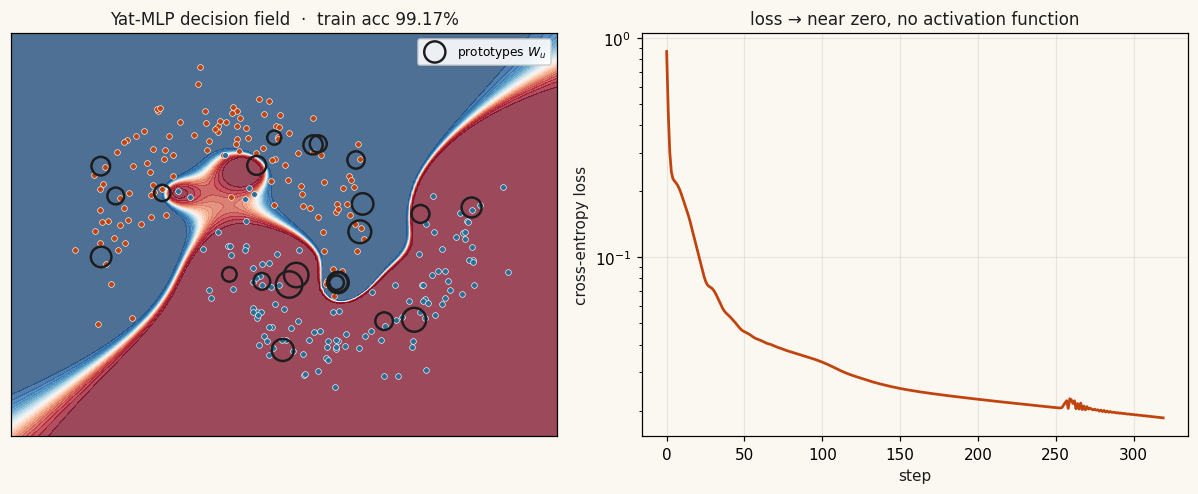

In [9]:
# decision field over a grid, straight from the trained model
gx = jnp.linspace(-2.6, 2.6, 240); gy = jnp.linspace(-2.6, 2.6, 240)
GX, GY = jnp.meshgrid(gx, gy)
grid = jnp.stack([GX.ravel(), GY.ravel()], -1)
prob1 = jax.nn.softmax(model(grid), -1)[:, 1].reshape(GX.shape)

Wlearn = np.array(model.yat.W.value)                     # learned prototypes
rweight = np.linalg.norm(np.array(model.readout.kernel.value), axis=1)  # readout magnitude per unit
acc = float((model(X).argmax(-1) == y).mean())

fig, (ax, axl) = plt.subplots(1, 2, figsize=(11, 4.6), facecolor=PAPER)
ax.set_facecolor(PAPER)
ax.contourf(np.array(GX), np.array(GY), np.array(prob1), levels=24, cmap='RdBu_r', alpha=0.72)
for c, col in [(0, C0), (1, C1)]:
    m = y_np == c
    ax.scatter(X_np[m, 0], X_np[m, 1], s=14, c=col, edgecolors='white', linewidths=0.4, zorder=3)
ax.scatter(Wlearn[:, 0], Wlearn[:, 1], s=40 + 260 * rweight / rweight.max(),
           facecolors='none', edgecolors=INK, linewidths=1.6, zorder=4, label='prototypes $W_u$')
ax.set_title(f'Yat-MLP decision field  ·  train acc {acc:.2%}', color=INK, fontsize=11)
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc='upper right', fontsize=8, framealpha=0.9)

axl.set_facecolor(PAPER)
axl.plot(loss_hist, color=C0, lw=1.8)
axl.set_yscale('log'); axl.set_xlabel('step', color=INK); axl.set_ylabel('cross-entropy loss', color=INK)
axl.set_title('loss → near zero, no activation function', color=INK, fontsize=11)
axl.grid(alpha=0.25)
fig.tight_layout()
p = PUB / 'yat-mlp-decision-field.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

### Figure: the shape of the kernel, a single localized peak

Before measuring affordances, look at what the unit *is*. The left panel is the Yat response field $k_{b,\varepsilon}(W, x)$ over input space for a single prototype $W$ at the marked point, with the learned $b,\varepsilon$: a single localized peak at the center that decays in every direction. The right panel is the same kernel on normalized inputs reduced to the cosine similarity $S=\langle x, W\rangle$, $k^\circ(S) = (S+b)^2/(\varepsilon + 2 - 2S)$, a clean bump maximal at $S=1$. Compare the ReLU response, a half-plane ramp with no "near": that contrast is the source of everything below.

<>:28: SyntaxWarning: invalid escape sequence '\c'
<>:29: SyntaxWarning: invalid escape sequence '\c'
<>:28: SyntaxWarning: invalid escape sequence '\c'
<>:29: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_16/351951726.py:28: SyntaxWarning: invalid escape sequence '\c'
  axes[2].set_xlabel('cosine similarity  $S = x \cdot W$', color=INK)
/tmp/ipykernel_16/351951726.py:29: SyntaxWarning: invalid escape sequence '\c'
  axes[2].set_ylabel('$k^\circ(S)$', color=INK)
/tmp/ipykernel_16/351951726.py:1: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  b_l = float(jax.nn.softplus(model.yat.log_b.value))
/tmp/ipykernel_16/351951726.py:2: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  eps_l = float(jax.nn.softplus(model.yat.log_eps.value))



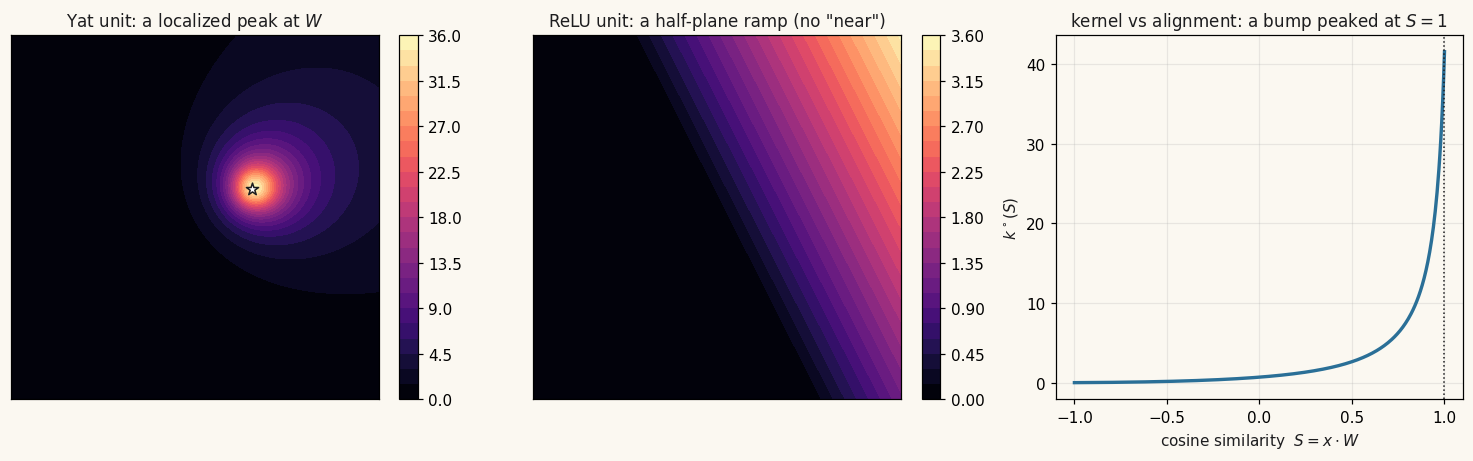

In [10]:
b_l = float(jax.nn.softplus(model.yat.log_b.value))
eps_l = float(jax.nn.softplus(model.yat.log_eps.value))
Wc = jnp.array([0.8, 0.4])                               # one prototype

def yat_field(Xpts, W, b, eps):
    cross = Xpts @ W
    return (cross + b) ** 2 / (jnp.sum(Xpts**2, -1) + jnp.sum(W**2) - 2*cross + eps)

field = yat_field(grid, Wc, b_l, eps_l).reshape(GX.shape)
relu_field = jnp.maximum(grid @ (Wc / jnp.linalg.norm(Wc)), 0.0).reshape(GX.shape)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), facecolor=PAPER)
for a in axes: a.set_facecolor(PAPER)
im0 = axes[0].contourf(np.array(GX), np.array(GY), np.array(field), levels=26, cmap='magma')
axes[0].scatter([float(Wc[0])], [float(Wc[1])], s=70, marker='*', c='white', edgecolors=INK, zorder=3)
axes[0].set_title('Yat unit: a localized peak at $W$', color=INK, fontsize=11)
axes[0].set_xticks([]); axes[0].set_yticks([]); fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].contourf(np.array(GX), np.array(GY), np.array(relu_field), levels=26, cmap='magma')
axes[1].set_title('ReLU unit: a half-plane ramp (no "near")', color=INK, fontsize=11)
axes[1].set_xticks([]); axes[1].set_yticks([]); fig.colorbar(im1, ax=axes[1], fraction=0.046)

S = jnp.linspace(-1, 1, 400)
kcirc = (S + b_l) ** 2 / (eps_l + 2 - 2 * S)
axes[2].set_facecolor(PAPER)
axes[2].plot(np.array(S), np.array(kcirc), color=C1, lw=2.2)
axes[2].axvline(1.0, color=INK, ls=':', lw=1)
axes[2].set_xlabel('cosine similarity  $S = x \cdot W$', color=INK)
axes[2].set_ylabel('$k^\circ(S)$', color=INK)
axes[2].set_title('kernel vs alignment: a bump peaked at $S=1$', color=INK, fontsize=11)
axes[2].grid(alpha=0.25)
fig.tight_layout()
p = PUB / 'yat-kernel-shape.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

## Lazy loading: the layer fires a handful of units

Because each unit is peaked at its center, only the prototypes near an input respond. The hidden layer is **sparse by construction**, which is the basis for fetching only the active units instead of evaluating the whole layer, conditional computation that falls out of the *geometry* of the unit rather than a learned gating network. A ReLU layer cannot do this: a ReLU unit is active on half of all inputs, so there is no neighborhood to exploit.

In [11]:
layer = YatLayer(2, 64, rngs=nnx.Rngs(0))
Xb = jax.random.normal(jax.random.key(3), (200, 2))
act = layer(Xb)                                          # [200, 64] kernel activations
frac_yat = float(jnp.mean(act >= 0.18 * act.max(-1, keepdims=True)))

relu = jnp.maximum(Xb @ jax.random.normal(jax.random.key(4), (2, 64)), 0.0)
frac_relu = float(jnp.mean(relu > 0))
print(f"active fraction, Yat {frac_yat*100:.0f}%   ReLU {frac_relu*100:.0f}%")   # Yat 25%  ReLU 50%

/tmp/ipykernel_16/1658386242.py:9: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  b = jax.nn.softplus(self.log_b.value)
/tmp/ipykernel_16/1658386242.py:10: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  eps = jax.nn.softplus(self.log_eps.value)
/tmp/ipykernel_16/1658386242.py:11: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  dot = x @ self.W.value.T                        # [..., n_units]  = x·Wᵤ
/tmp/ipykernel_16/1658386242.py:13: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  wn = jnp.sum(self.W.value ** 2, -1)         

active fraction, Yat 26%   ReLU 50%


## Bounded off the distribution

Drive a ReLU unit far from the data and it climbs without bound, a large, confident answer for an input it has never seen. The Yat unit stays **bounded**: its response far away is a fraction of its in-data peak, never an extrapolated cliff. Abstention and OOD-awareness are not a separate detection head; they are what a local kernel does when you leave the data.

In [12]:
xs = jnp.linspace(-50, 50, 4001)
yat_1d  = (xs + 0.6) ** 2 / (xs ** 2 + 0.3)
relu_1d = jnp.maximum(xs + 0.6, 0.0)
print("sup |Yat| :", float(jnp.max(yat_1d)))    # 2.20, bounded over the whole range
print("sup  ReLU :", float(jnp.max(relu_1d)))   # 50.6, grows with the range

assert jnp.max(yat_1d) < 5.0                     # bounded no matter how far off-distribution

sup |Yat| : 2.200000047683716
sup  ReLU : 50.599998474121094


### Figure: the sparse active set, and the bounded tail

Two faithful panels from the numbers just computed. Left: the per-input count of active Yat units versus active ReLU units across the 200 random inputs, the Yat layer fires a small, tight slice; the ReLU layer fires half of everything. Right: the 1-D Yat unit and the ReLU pre-activation over a wide range, with the data band shaded. The ReLU ramp climbs out of the top of the plot; the Yat response is a small, bounded bump.


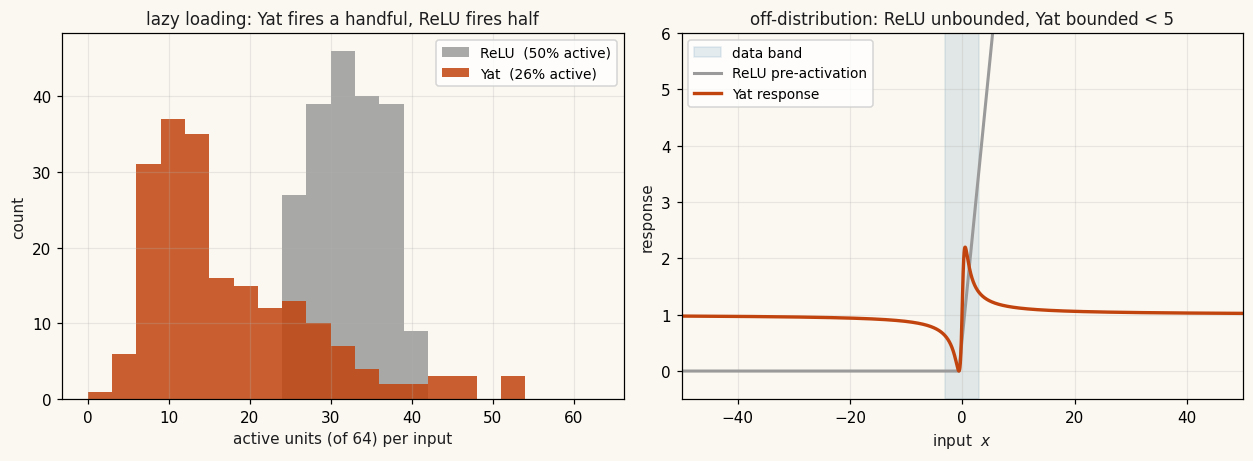

In [13]:
yat_counts = np.array(jnp.sum(act >= 0.18 * act.max(-1, keepdims=True), -1))
relu_counts = np.array(jnp.sum(relu > 0, -1))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 4.3), facecolor=PAPER)
ax0.set_facecolor(PAPER)
bins = np.arange(0, 65, 3)
ax0.hist(relu_counts, bins=bins, color='#9a9a9a', alpha=0.85, label=f'ReLU  ({frac_relu*100:.0f}% active)')
ax0.hist(yat_counts, bins=bins, color=C0, alpha=0.85, label=f'Yat  ({frac_yat*100:.0f}% active)')
ax0.set_xlabel('active units (of 64) per input', color=INK); ax0.set_ylabel('count', color=INK)
ax0.set_title('lazy loading: Yat fires a handful, ReLU fires half', color=INK, fontsize=11)
ax0.legend(fontsize=9); ax0.grid(alpha=0.25)

ax1.set_facecolor(PAPER)
xsn = np.array(xs)
ax1.axvspan(-3, 3, color=C1, alpha=0.12, label='data band')
ax1.plot(xsn, np.array(relu_1d), color='#9a9a9a', lw=2, label='ReLU pre-activation')
ax1.plot(xsn, np.array(yat_1d), color=C0, lw=2.2, label='Yat response')
ax1.set_ylim(-0.5, 6); ax1.set_xlim(-50, 50)
ax1.set_xlabel('input  $x$', color=INK); ax1.set_ylabel('response', color=INK)
ax1.set_title('off-distribution: ReLU unbounded, Yat bounded < 5', color=INK, fontsize=11)
ax1.legend(fontsize=9, loc='upper left'); ax1.grid(alpha=0.25)
fig.tight_layout()
p = PUB / 'yat-lazy-and-ood.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

## Capacity you can compute, and a force that never vanishes

Kernel machines come with a complexity measure that generalization bounds actually use: the RKHS norm. For the Yat unit that norm at its peak is the computable scalar $(\lVert W\rVert^2 + b)^2/\varepsilon$, a real measure of how sharply it is tuned, and a direct target for regularization through $\varepsilon$. And because the kernel is smooth everywhere, the gradient that pulls a prototype toward its data **never vanishes**, there is no dead half-space the way a saturated ReLU has. Units do not die; they migrate.

Below, the force on a prototype is $-\nabla_P L$ of an objective that rewards kernel response to class A and penalizes class B, an exact gradient. Over 50 random probe positions the minimum force magnitude is strictly positive: force everywhere, no dead zone.

In [14]:
W0 = jnp.array([1.0, 0.5])
print("capacity (‖W‖²+b)²/ε:", float((jnp.sum(W0**2) + 0.5) ** 2 / 0.25))   # 12.25

# two class clusters for the detector objective
XA = jnp.array(X_np[y_np == 0], jnp.float32)             # class A points
XB = jnp.array(X_np[y_np == 1], jnp.float32)             # class B points

# the force on a prototype = −∇ of an objective that makes it a class detector
def k(P, Xpts, b=0.5, eps=0.4):
    cross = Xpts @ P
    return (cross + b) ** 2 / (jnp.sum(Xpts**2, 1) + jnp.sum(P**2) - 2*cross + eps)
L = lambda P: k(P, XB).mean() - k(P, XA).mean()          # attract to A, repel from B
probes = jax.random.normal(jax.random.key(7), (50, 2)) * 1.5
forces = jax.vmap(jax.grad(L))(probes)
print("min ‖force‖ over 50 probes:", float(jnp.min(jnp.linalg.norm(forces, axis=1))))  # > 0

assert jnp.min(jnp.linalg.norm(forces, axis=1)) > 1e-4   # force everywhere, no dead zone

capacity (‖W‖²+b)²/ε: 12.25
min ‖force‖ over 50 probes: 0.4943838119506836


### Animation: a prototype migrating down the real force field

The required GIF, every frame a real backward pass. We draw the force field $-\nabla_P L$ over input space (the same objective: detect class A, avoid class B), then drop a probe prototype and integrate gradient descent on $L$. The probe flows along the field and **migrates onto the class-A cluster**, the data it should detect. There is force everywhere, so it never gets stuck, which is exactly why a Yat unit never dies the way a ReLU unit can. The trajectory is the actual optimization path, not a scripted curve.


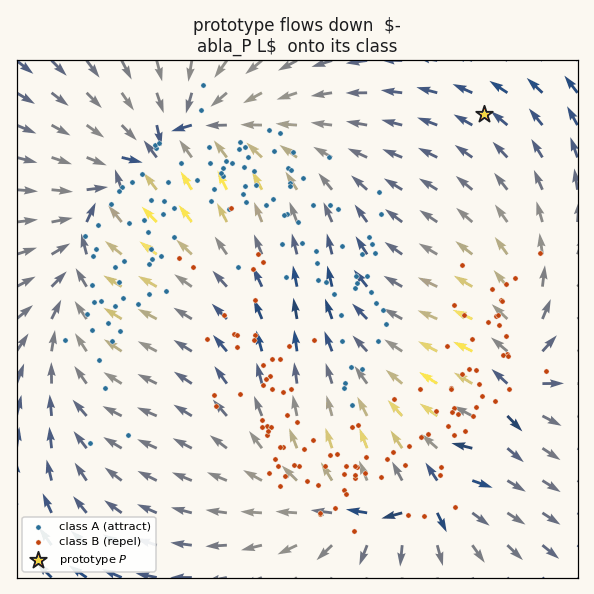

In [15]:
# real negative-gradient field of L over a coarse grid (each arrow is a backward pass)
fg = jnp.linspace(-2.4, 2.4, 17)
FGX, FGY = jnp.meshgrid(fg, fg)
fgrid = jnp.stack([FGX.ravel(), FGY.ravel()], -1)
fvec = -jax.vmap(jax.grad(L))(fgrid)                     # negative gradient = the force
U = np.array(fvec[:, 0]).reshape(FGX.shape); V = np.array(fvec[:, 1]).reshape(FGX.shape)
mag = np.hypot(U, V) + 1e-9
Un, Vn = U / mag, V / mag                                # unit arrows, color by magnitude

# integrate one probe down the real gradient (this IS the migration)
gL = jax.grad(L)
P = jnp.array([1.6, 1.9])                                # start in class-B territory
lr, traj = 0.06, [np.array(P)]
for _ in range(60):
    P = P - lr * gL(P)
    traj.append(np.array(P))
traj = np.array(traj)

frames = []
for i in range(0, len(traj), 2):
    fig, ax = plt.subplots(figsize=(5.4, 5.4), facecolor=PAPER); ax.set_facecolor(PAPER)
    ax.quiver(np.array(FGX), np.array(FGY), Un, Vn, mag, cmap='cividis',
              scale=26, width=0.005, alpha=0.85)
    ax.scatter(np.array(XA)[:, 0], np.array(XA)[:, 1], s=12, c=C1, edgecolors='white',
               linewidths=0.3, label='class A (attract)', zorder=2)
    ax.scatter(np.array(XB)[:, 0], np.array(XB)[:, 1], s=12, c=C0, edgecolors='white',
               linewidths=0.3, label='class B (repel)', zorder=2)
    ax.plot(traj[:i+1, 0], traj[:i+1, 1], color=INK, lw=1.4, zorder=3)
    ax.scatter([traj[i, 0]], [traj[i, 1]], s=130, marker='*', c='gold',
               edgecolors=INK, linewidths=1.2, zorder=4, label='prototype $P$')
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title('prototype flows down  $-\nabla_P L$  onto its class', color=INK, fontsize=11)
    if i == 0: ax.legend(loc='lower left', fontsize=7.5, framealpha=0.9)
    fig.tight_layout()
    fig.canvas.draw()
    frame = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    frames.append(frame); plt.close(fig)
frames += [frames[-1]] * 8                                # hold on the final position
gif = PUB / 'yat-prototype-migration.gif'
imageio.mimsave(gif, frames, duration=0.09, loop=0)
display(_img(gif))

## More

A few more views, each computed from the objects already built, no synthetic fields.

### Prototypes before and after training: feature learning, drawn

The explainer's central claim is that the prototypes are **parameters that move**, the feature-learning regime, not the NTK's frozen kernel. We snapshotted the 24 prototypes before training (`W0_proto`) and we have them after (`Wlearn`). Here they are over the data, arrows from each starting position to its learned position, colored by the class its readout weight votes for. The centers migrate off their random scatter and onto the moons.

/tmp/ipykernel_16/712326898.py:1: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  vote = np.array(model.readout.kernel.value).argmax(1)   # which class each unit pushes



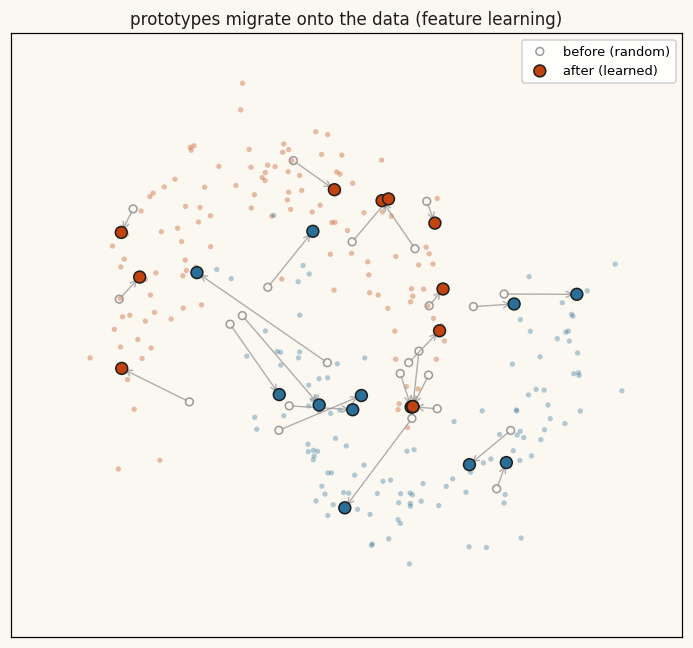

In [16]:
vote = np.array(model.readout.kernel.value).argmax(1)   # which class each unit pushes
cols = np.where(vote == 0, C0, C1)

fig, ax = plt.subplots(figsize=(6.4, 6.0), facecolor=PAPER); ax.set_facecolor(PAPER)
for c, col in [(0, C0), (1, C1)]:
    m = y_np == c
    ax.scatter(X_np[m, 0], X_np[m, 1], s=12, c=col, alpha=0.35, edgecolors='none', zorder=1)
for i in range(W0_proto.shape[0]):
    ax.annotate('', xy=Wlearn[i], xytext=W0_proto[i],
                arrowprops=dict(arrowstyle='->', color='#9a9a9a', lw=0.9, alpha=0.8), zorder=2)
ax.scatter(W0_proto[:, 0], W0_proto[:, 1], s=26, facecolors='none',
           edgecolors='#9a9a9a', linewidths=1.0, label='before (random)', zorder=3)
ax.scatter(Wlearn[:, 0], Wlearn[:, 1], s=60, c=cols, edgecolors=INK,
           linewidths=1.0, label='after (learned)', zorder=4)
ax.set_title('prototypes migrate onto the data (feature learning)', color=INK, fontsize=11)
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc='upper right', fontsize=8.5, framealpha=0.9)
fig.tight_layout()
p = PUB / 'yat-prototype-migration-static.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

### Exact attribution: the representer theorem, no surrogate

By the representer theorem (Kimeldorf & Wahba, 1971; Schölkopf et al., 2001), the readout is a weighted sum of kernel evaluations, so the contribution of center $u$ to an output is the kernel weight itself, an **exact** number, not a LIME/SHAP approximation. Normalizing the nonnegative kernel activations gives a convex partition $a_u = k(x, W_u)/\sum_v k(x, W_v)$, "unit $u$ accounts for 30% of this output" as a true statement. We pick a real query point from the data, compute its kernel activations against the **learned** prototypes, and show the top contributors as a convex bar chart that sums to one.

<>:24: SyntaxWarning: invalid escape sequence '\s'
<>:24: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_16/1950528379.py:24: SyntaxWarning: invalid escape sequence '\s'
  axb.set_title(f'convex attribution, $\sum a_u = {a.sum():.2f}$', color=INK, fontsize=11)
/tmp/ipykernel_16/1658386242.py:9: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  b = jax.nn.softplus(self.log_b.value)
/tmp/ipykernel_16/1658386242.py:10: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  eps = jax.nn.softplus(self.log_eps.value)
/tmp/ipykernel_16/1658386242.py:11: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  dot = x @ self.W.value.T                     


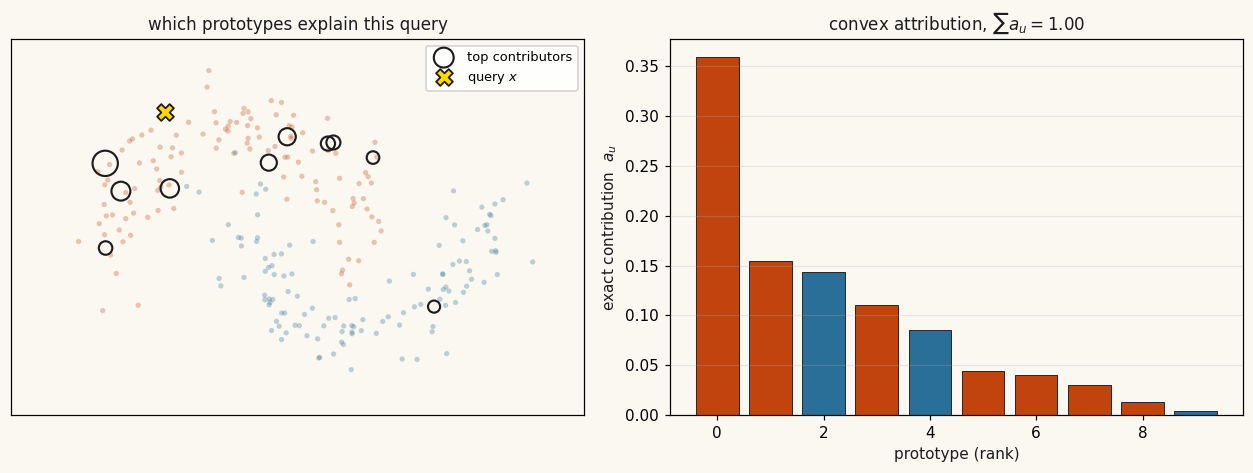

In [17]:
q = X[10]                                                # a real query point
act_q = np.array(model.yat(q[None])[0])                  # kernel activations against learned prototypes
a = np.clip(act_q, 0, None); a = a / a.sum()             # convex attribution weights (sum to 1)
order = np.argsort(a)[::-1][:10]                          # top-10 contributing prototypes
votes = np.array(model.readout.kernel.value).argmax(1)

fig, (axc, axb) = plt.subplots(1, 2, figsize=(11.5, 4.4), facecolor=PAPER)
axc.set_facecolor(PAPER)
for c, col in [(0, C0), (1, C1)]:
    m = y_np == c
    axc.scatter(X_np[m, 0], X_np[m, 1], s=12, c=col, alpha=0.3, edgecolors='none')
axc.scatter(Wlearn[order, 0], Wlearn[order, 1], s=60 + 600 * a[order], facecolors='none',
            edgecolors=INK, linewidths=1.4, zorder=3, label='top contributors')
axc.scatter([float(q[0])], [float(q[1])], s=120, marker='X', c='gold',
            edgecolors=INK, linewidths=1.2, zorder=4, label='query $x$')
axc.set_title('which prototypes explain this query', color=INK, fontsize=11)
axc.set_xlim(-2.6, 2.6); axc.set_ylim(-2.6, 2.6); axc.set_xticks([]); axc.set_yticks([])
axc.legend(loc='upper right', fontsize=8.5, framealpha=0.9)

axb.set_facecolor(PAPER)
barcols = [C0 if votes[i] == 0 else C1 for i in order]
axb.bar(range(len(order)), a[order], color=barcols, edgecolor=INK, linewidth=0.6)
axb.set_xlabel('prototype (rank)', color=INK); axb.set_ylabel('exact contribution  $a_u$', color=INK)
axb.set_title(f'convex attribution, $\sum a_u = {a.sum():.2f}$', color=INK, fontsize=11)
axb.grid(alpha=0.25, axis='y')
fig.tight_layout()
p = PUB / 'yat-attribution.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

### The kernel trick, in the exact finite feature space

The finite feature map makes a *curved* boundary in input space a *flat* one upstairs. We take two concentric rings (no line separates them in 2-D), lift them along the degree-2 feature $x_1^2 + x_2^2$, and fit a single **flat plane** in the 6-D feature space with a least-squares solve, exactly the kernel trick on the real $\phi$. On the floor that flat plane projects back to a circle. This is computed, not drawn: the lift is the real quadratic feature and the separating height is the real fit.

<>:31: SyntaxWarning: invalid escape sequence '\p'
<>:32: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\p'
<>:32: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_16/1159378521.py:31: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title(f'lift by exact $\phi$: a flat plane splits the rings (acc {sep_acc:.0%})', color=INK, fontsize=11)
/tmp/ipykernel_16/1159378521.py:32: SyntaxWarning: invalid escape sequence '\p'
  ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_zlabel('feature score $\phi(x)\!\cdot\! w$')



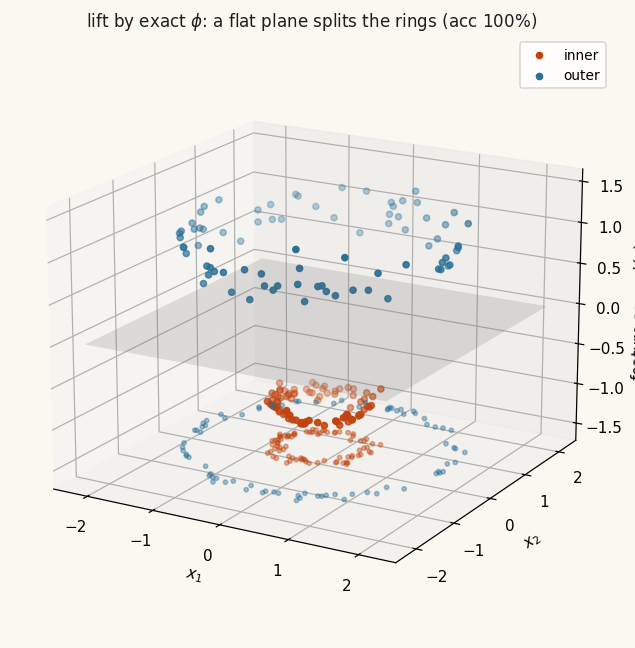

In [18]:
from mpl_toolkits.mplot3d import Axes3D  # noqa

key = jax.random.key(11)
n = 160
r = jnp.concatenate([0.6 * jnp.ones(n // 2), 1.8 * jnp.ones(n // 2)])
th = jax.random.uniform(key, (n,)) * 2 * np.pi
ring = jnp.stack([r * jnp.cos(th), r * jnp.sin(th)], -1)
ring = ring + jax.random.normal(jax.random.key(12), (n, 2)) * 0.07
lab = jnp.concatenate([jnp.zeros(n // 2), jnp.ones(n // 2)])      # inner=0, outer=1

Phi = np.array(phi_x(ring))                               # exact degree-2 features, R⁶
labv = np.array(lab) * 2 - 1                              # ±1 targets
w_ls, *_ = np.linalg.lstsq(Phi, labv, rcond=None)         # flat separator in feature space (real fit)
score = Phi @ w_ls                                        # the height that flattens the problem
sep_acc = float(((score > 0).astype(int) == np.array(lab)).mean())

ringn = np.array(ring); labn = np.array(lab)
fig = plt.figure(figsize=(7.2, 6.0), facecolor=PAPER)
ax = fig.add_subplot(111, projection='3d'); ax.set_facecolor(PAPER)
for c, col, nm in [(0, C0, 'inner'), (1, C1, 'outer')]:
    m = labn == c
    ax.scatter(ringn[m, 0], ringn[m, 1], score[m], s=16, c=col, depthshade=True, label=nm)
# the flat separating plane sits at score = 0
xx, yy = np.meshgrid(np.linspace(-2.2, 2.2, 8), np.linspace(-2.2, 2.2, 8))
ax.plot_surface(xx, yy, np.zeros_like(xx), alpha=0.18, color='#888888')
# shadow on the floor
zfloor = score.min() - 0.4
for c, col in [(0, C0), (1, C1)]:
    m = labn == c
    ax.scatter(ringn[m, 0], ringn[m, 1], zfloor, s=8, c=col, alpha=0.4)
ax.set_title(f'lift by exact $\phi$: a flat plane splits the rings (acc {sep_acc:.0%})', color=INK, fontsize=11)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_zlabel('feature score $\phi(x)\!\cdot\! w$')
ax.legend(fontsize=9); ax.view_init(elev=18, azim=-60)
fig.tight_layout()
p = PUB / 'yat-kernel-trick-lift.png'; fig.savefig(p, facecolor=PAPER, bbox_inches='tight'); plt.close(fig)
display(_img(p))

## Gallery

Every figure and animation this notebook produced, inline, from `/kaggle/working`.

1 animations + 6 figures in /kaggle/working
/kaggle/working/yat-prototype-migration.gif



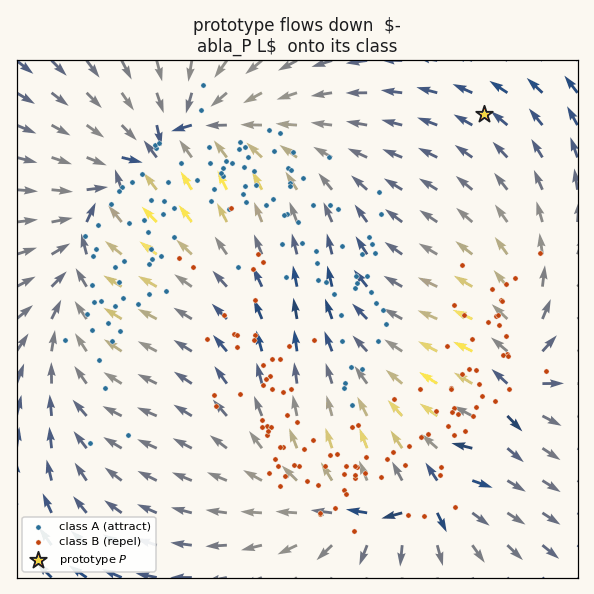

/kaggle/working/yat-attribution.png



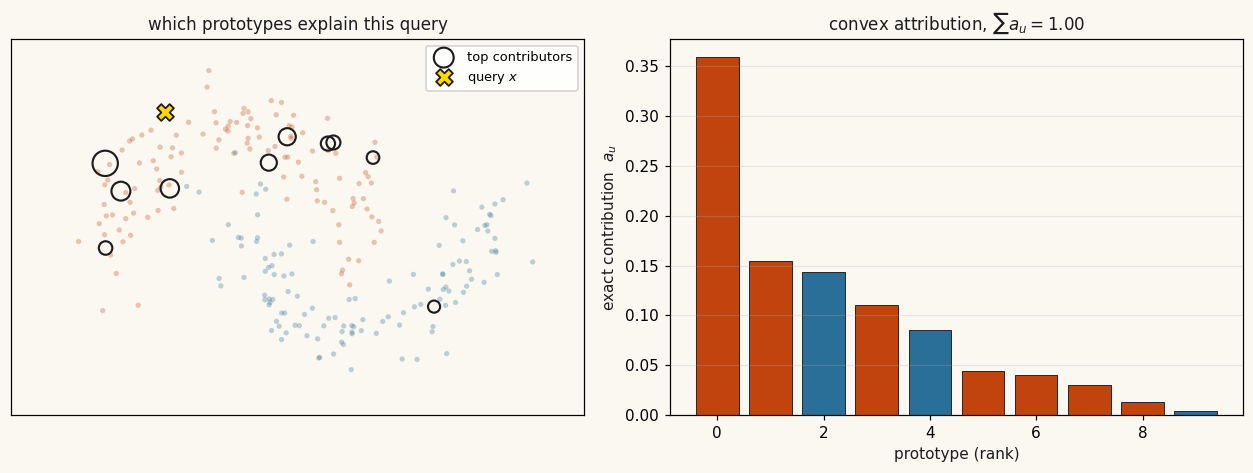

/kaggle/working/yat-kernel-shape.png



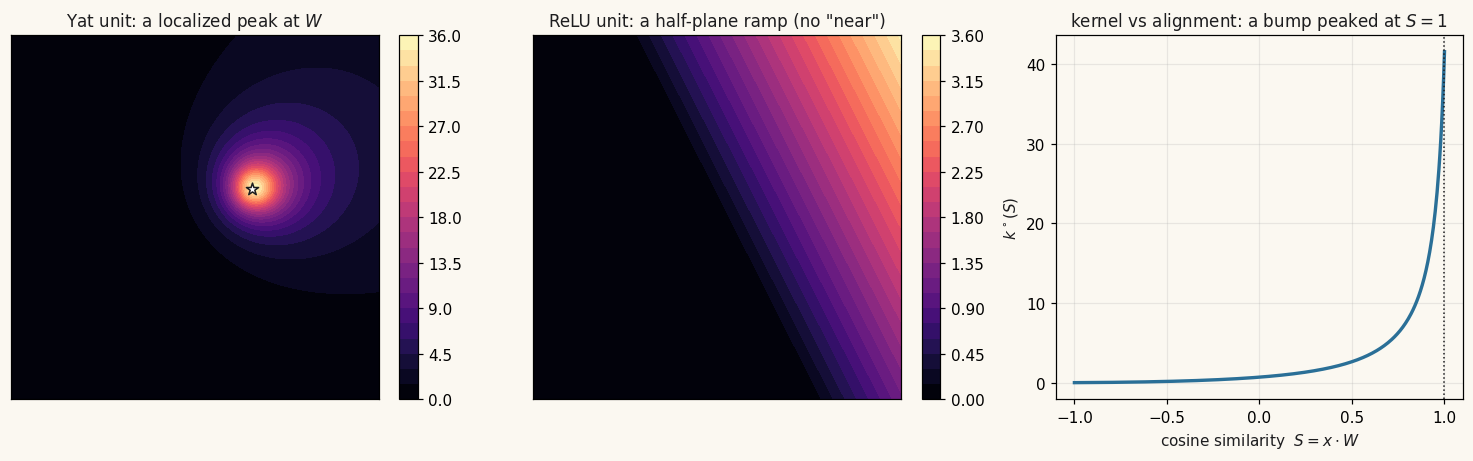

/kaggle/working/yat-kernel-trick-lift.png



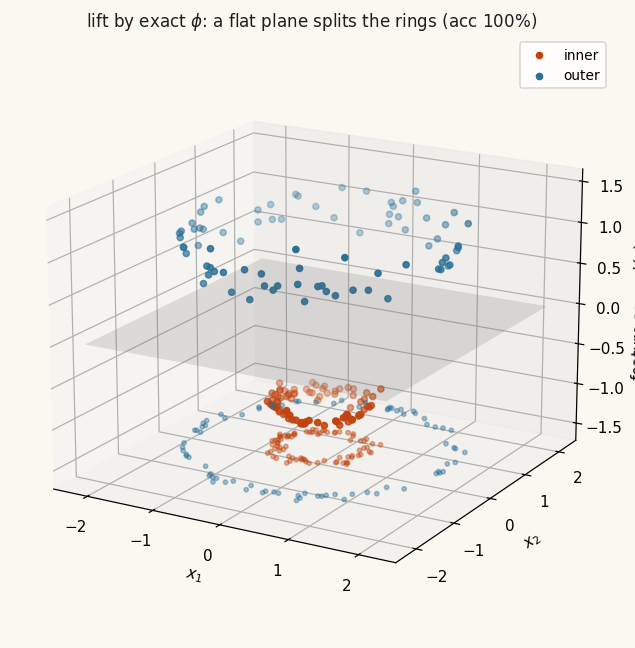

/kaggle/working/yat-lazy-and-ood.png



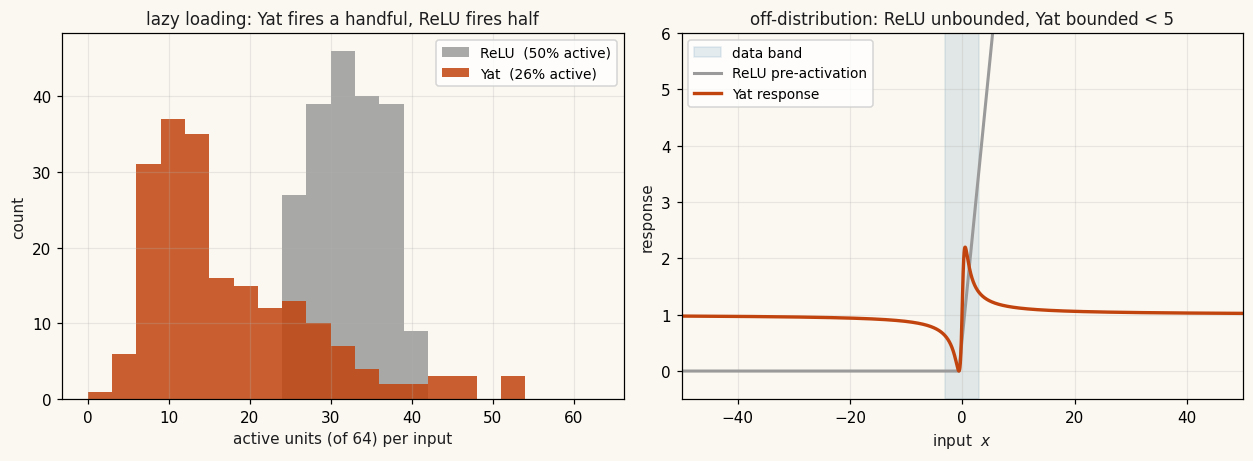

/kaggle/working/yat-mlp-decision-field.png



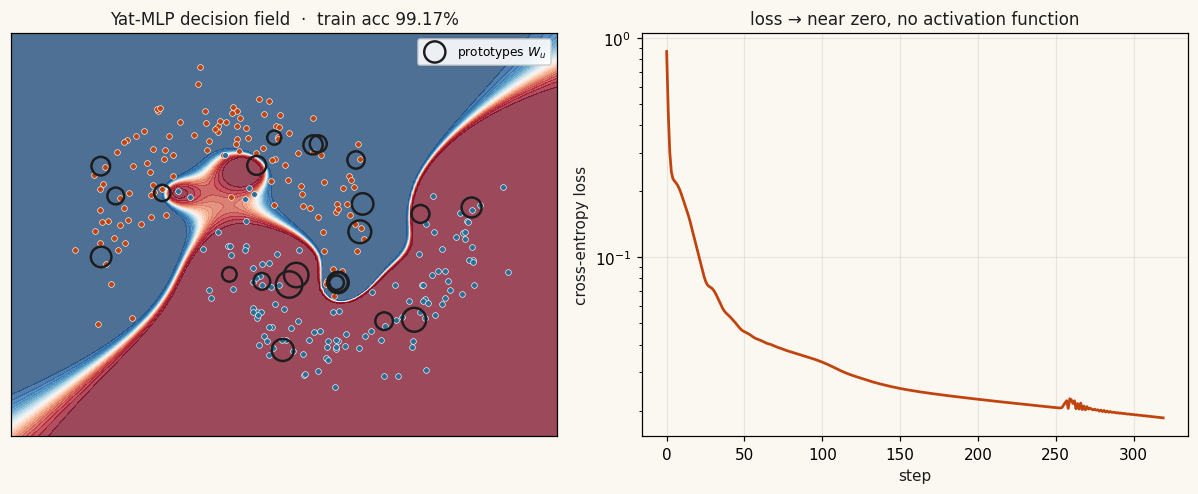

/kaggle/working/yat-prototype-migration-static.png



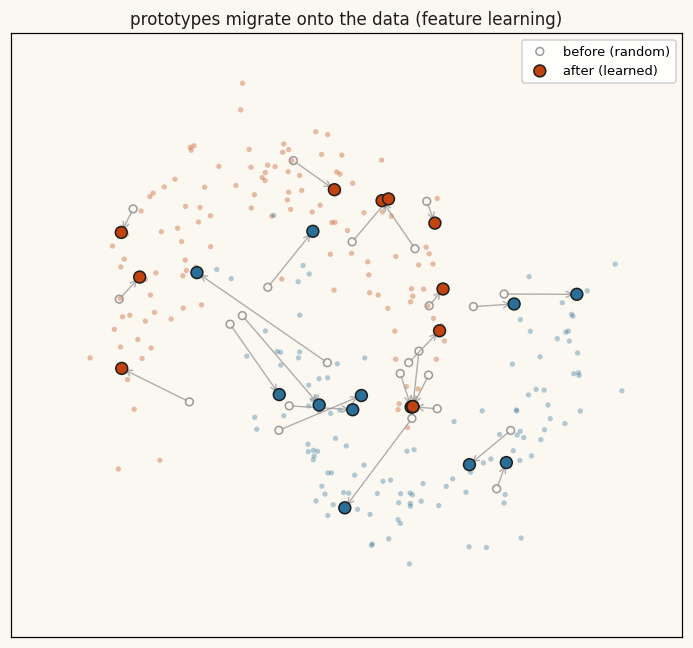

In [19]:
import glob
gifs = sorted(glob.glob(str(PUB / '*.gif')))
pngs = [f for f in sorted(glob.glob(str(PUB / '*.png'))) if not f.endswith('-preview.png')]
print(f'{len(gifs)} animations + {len(pngs)} figures in {PUB}')
for f in gifs + pngs:
    print(f); display(_img(f))